## Challenge 2: Music Genre Classification
## Tập dữ liệu: shai-music-genre-classification
## Sử dụng 3 thuật toán: LightGBM, XGBoost, Random Forest
## Độ đo: F1

### 1. Đọc dữ liệu

In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

SEED = 42
TARGET = "Class"

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
sample_sub = pd.read_csv("data/sample_submission.csv")

print("Train:", train.shape, "| Test:", test.shape, "| Sample submission:", sample_sub.shape)
train.head()

Train: (14396, 18) | Test: (3600, 17) | Sample submission: (3600, 2)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


### 2. Khám phá dữ liệu EDA

In [12]:
print(train.dtypes, "\n")

miss = pd.DataFrame({"train": train.isnull().sum(), "test": test.isnull().sum().reindex(train.columns)})
print("Giá trị thiếu:")
print(miss[(miss["train"] > 0) | (miss["test"] > 0)], "\n")

feat_cols = [c for c in train.columns if c not in ("Id", TARGET)]
print("Dòng trùng hoàn toàn (bỏ Id)              :", train.drop(columns="Id").duplicated().sum())
print("Dòng giống hệt đặc trưng nhưng khác Class :", train.duplicated(feat_cols, keep=False).sum())

Id                      int64
Artist Name               str
Track Name                str
Popularity            float64
danceability          float64
energy                float64
key                   float64
loudness              float64
mode                    int64
speechiness           float64
acousticness          float64
instrumentalness      float64
liveness              float64
valence               float64
tempo                 float64
duration_in min/ms    float64
time_signature          int64
Class                   int64
dtype: object 

Giá trị thiếu:
                  train   test
Popularity          333   95.0
key                1609  405.0
instrumentalness   3541  836.0 

Dòng trùng hoàn toàn (bỏ Id)              : 0
Dòng giống hệt đặc trưng nhưng khác Class : 2060


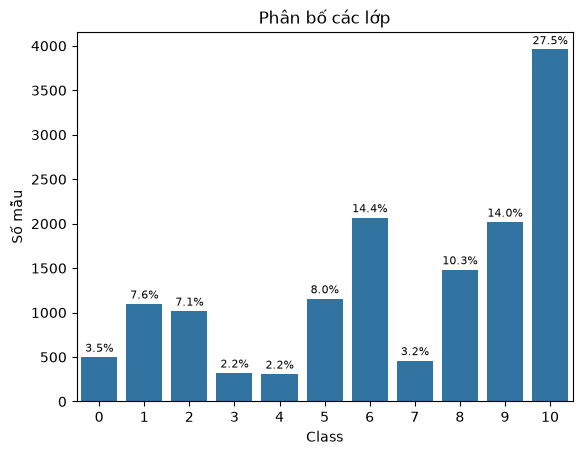

In [13]:
cnt = train[TARGET].value_counts().sort_index()
ax = sns.barplot(x=cnt.index, y=cnt.values, color="tab:blue")
for i, v in enumerate(cnt.values):
    ax.text(i, v + 60, f"{v / len(train) * 100:.1f}%", ha="center", fontsize=8)
ax.set_xlabel("Class"); ax.set_ylabel("Số mẫu"); ax.set_title("Phân bố các lớp")
plt.show()

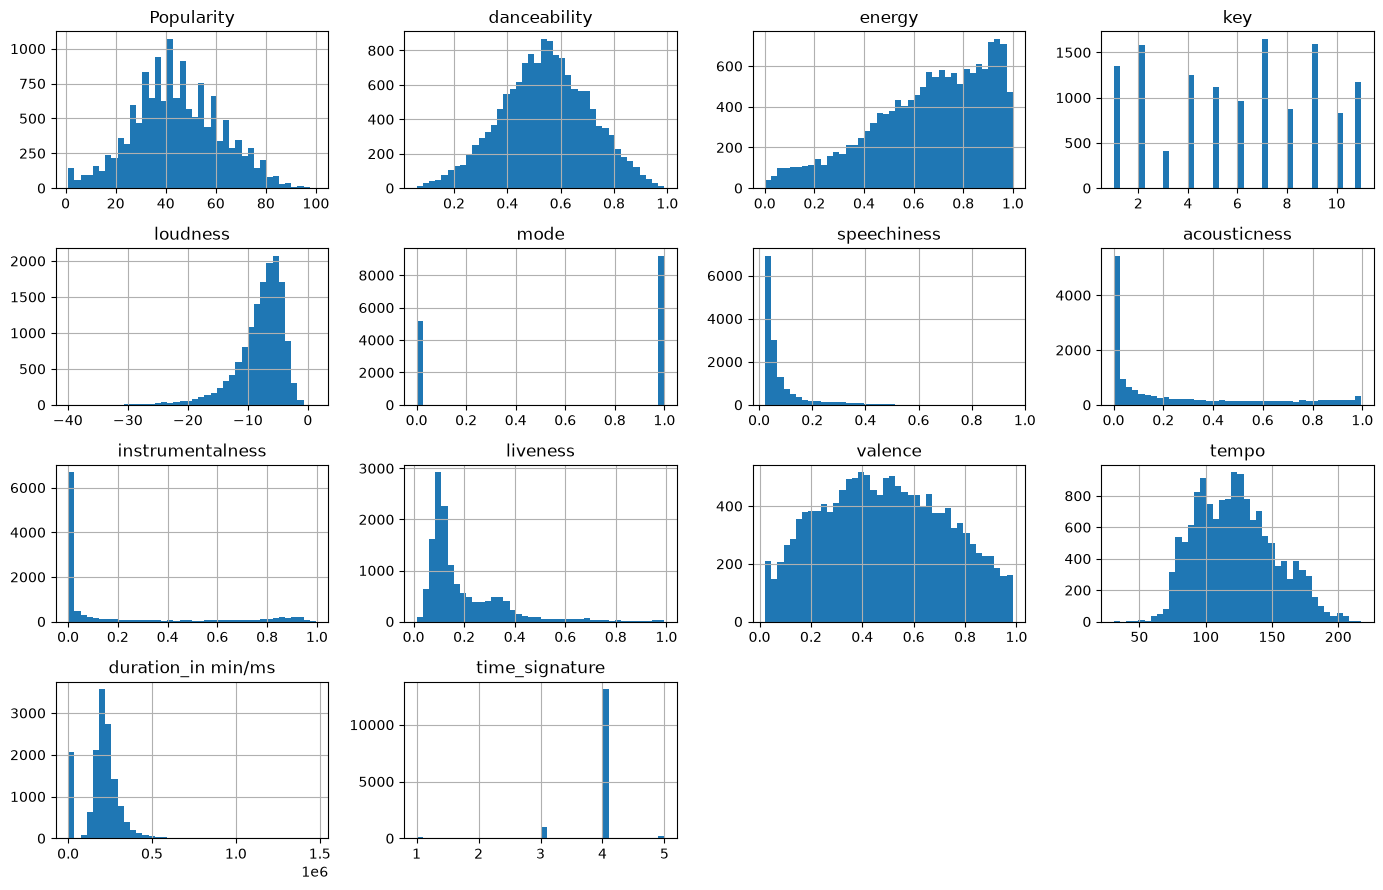

Số dòng duration < 1000 (nghi là đơn vị phút): train 2075, test 505


In [14]:
NUM_COLS = ["Popularity", "danceability", "energy", "key", "loudness", "mode", "speechiness",
            "acousticness", "instrumentalness", "liveness", "valence", "tempo",
            "duration_in min/ms", "time_signature"]

train[NUM_COLS].hist(bins=40, figsize=(14, 9))
plt.tight_layout(); plt.show()

small = (train["duration_in min/ms"] < 1000).sum()
print(f"Số dòng duration < 1000 (nghi là đơn vị phút): train {small}, test {(test['duration_in min/ms'] < 1000).sum()}")

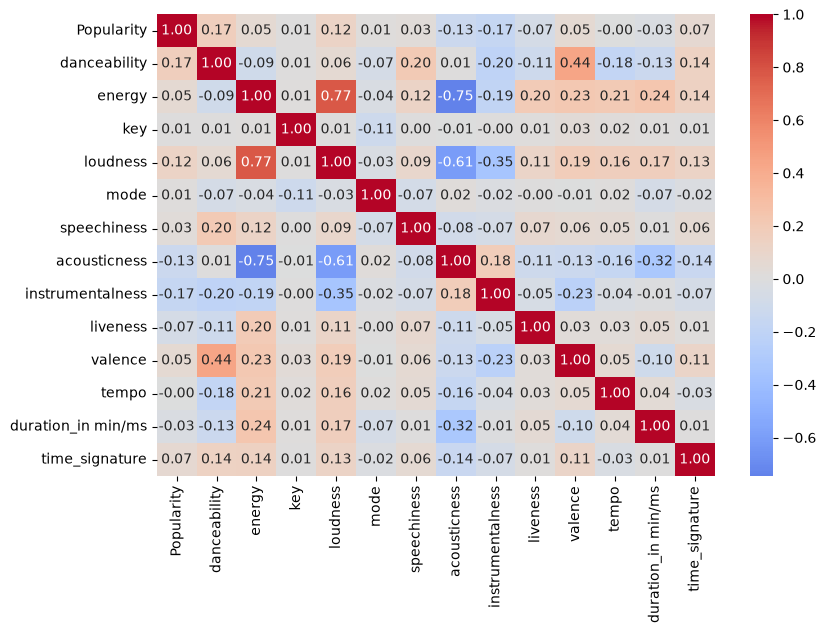

In [15]:
plt.figure(figsize=(9, 6))
sns.heatmap(train[NUM_COLS].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

**Nhận xét:**
- Train 14.396 dòng, test 3.600 dòng, target `Class` có 11 lớp.
- **Mất cân bằng lớp:** lớp 10 chiếm 27,5%, lớp 3 và 4 chỉ khoảng 2,2%. Do đó dùng F1 macro và xử lý mất cân bằng ở bước sau.
- **Giá trị thiếu:** `Popularity` (2,3%), `key` (11,2%), `instrumentalness` (24,6%), test thiếu tương tự.
- **Cột `duration`:** 2.075 dòng train (505 dòng test) có giá trị dưới 1000, trung vị khoảng 3,7, là đơn vị *phút* chứ không phải ms, cần đổi sang ms.
- **Trùng lặp:** không có dòng trùng hoàn toàn, nhưng 2.060 dòng giống hệt nhau về đặc trưng mà khác nhãn (cùng một bài thuộc nhiều genre). Đây là nhiễu nhãn, nên F1 không thể đạt gần 1.
- **Tương quan:** `energy` tương quan âm mạnh với `acousticness` (-0,75) và dương với `loudness` (0,77). Mô hình cây không bị ảnh hưởng nhiều.

### 3. Tiền xử lý dữ liệu

In [16]:
test_ids = test["Id"].copy()   # giữ lại để làm file nộp bài

def clean(df):
    df = df.copy()
    col = "duration_in min/ms"
    is_min = df[col] < 1000                       # giá trị đang ở đơn vị phút
    df.loc[is_min, col] = df.loc[is_min, col] * 60000
    df = df.rename(columns={col: "duration_ms"})
    return df.drop(columns=["Id", "Artist Name", "Track Name"])

train_c, test_c = clean(train), clean(test)

X = train_c.drop(columns=TARGET)
y = train_c[TARGET]
X_test = test_c

# Chia train/validation 80/20, giữ nguyên tỉ lệ các lớp
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

X_train: (11516, 14) | X_val: (2880, 14) | X_test: (3600, 14)


In [17]:
# Điền giá trị thiếu: tính từ tập train rồi áp dụng cho val và test (tránh rò rỉ dữ liệu)
fill = {
    "key": X_train["key"].mode()[0],
    "Popularity": X_train["Popularity"].median(),
    "instrumentalness": X_train["instrumentalness"].median(),
}
X_train, X_val, X_test = X_train.fillna(fill), X_val.fillna(fill), X_test.fillna(fill)

print("Còn thiếu (train/val/test):", X_train.isnull().sum().sum(), X_val.isnull().sum().sum(), X_test.isnull().sum().sum())

Còn thiếu (train/val/test): 0 0 0


In [18]:
os.makedirs("processed", exist_ok=True)
X_train.assign(**{TARGET: y_train}).to_csv("processed/train_split.csv", index=False)
X_val.assign(**{TARGET: y_val}).to_csv("processed/val_split.csv", index=False)
X_test.assign(Id=test_ids.values).to_csv("processed/test_processed.csv", index=False)
print("Đã lưu dữ liệu vào thư mục processed/")

Đã lưu dữ liệu vào thư mục processed/


### 4. Xử lý mất cân bằng

Dữ liệu huấn luyện có sự mất cân bằng giữa các lớp thể loại nhạc. Một số lớp có số lượng mẫu lớn, trong khi một số lớp chỉ chiếm tỷ lệ nhỏ. Điều này có thể khiến mô hình ưu tiên dự đoán các lớp chiếm đa số và làm giảm khả năng nhận diện các lớp thiểu số.

Nhóm sử dụng phương pháp Class Weight để điều chỉnh mức độ ảnh hưởng của từng lớp trong quá trình huấn luyện. Trọng số được tính theo nghịch đảo tần suất xuất hiện của từng lớp, giúp mô hình chú trọng hơn đến những lớp có ít dữ liệu.

Trọng số chỉ được tính từ tập huấn luyện. Tập validation được giữ nguyên phân phối ban đầu để đảm bảo đánh giá khách quan.

In [19]:

from sklearn.utils.class_weight import compute_class_weight

# Tính số lượng mẫu của từng lớp trên tập train
class_labels = np.sort(y_train.unique())
class_counts = y_train.value_counts().reindex(class_labels)

# Tính trọng số cho từng lớp
class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=class_labels,
    y=y_train
)

class_weights = dict(zip(class_labels, class_weight_values))

# Tạo bảng thống kê
imbalance_summary = pd.DataFrame({
    "Class": class_labels,
    "So mau": class_counts.values,
    "Ty le (%)": class_counts.values / len(y_train) * 100,
    "Trong so": class_weight_values
})

print("THỐNG KÊ MẤT CÂN BẰNG DỮ LIỆU")
display(imbalance_summary.round(4))

print("\nTrong số các lớp:")
print(class_weights)

THỐNG KÊ MẤT CÂN BẰNG DỮ LIỆU


,Class,So mau,Ty le (%),Trong so
0,0,400,3.4734,2.6173
1,1,878,7.6242,1.1924
2,2,814,7.0684,1.2861
3,3,258,2.2404,4.0578
4,4,248,2.1535,4.2214
5,5,926,8.0410,1.1306
6,6,1655,14.3713,0.6326
7,7,369,3.2042,2.8372
8,8,1186,10.2987,0.8827
9,9,1615,14.0240,0.6482



Trong số các lớp:
{np.int64(0): np.float64(2.617272727272727), np.int64(1): np.float64(1.1923793746117208), np.int64(2): np.float64(1.2861291043109224), np.int64(3): np.float64(4.0577871740662435), np.int64(4): np.float64(4.221407624633431), np.int64(5): np.float64(1.1305713724720203), np.int64(6): np.float64(0.6325734688272453), np.int64(7): np.float64(2.837152007883715), np.int64(8): np.float64(0.8827226736164342), np.int64(9): np.float64(0.6482409231635238), np.int64(10): np.float64(0.3305680741740104)}


### 5. Huấn luyện mô hình

#### 5.1 Mô hình LightGBM

Nhóm sử dụng thuật toán LightGBM để xây dựng mô hình phân loại thể loại nhạc. Mô hình được huấn luyện trên tập dữ liệu đã tiền xử lý, sử dụng các đặc trưng âm nhạc làm biến đầu vào và cột Class làm nhãn cần dự đoán.

Để đánh giá hiệu quả của phương pháp xử lý mất cân bằng, nhóm xây dựng hai mô hình LightGBM với cùng cấu hình tham số. Mô hình thứ nhất không sử dụng trọng số lớp, mô hình thứ hai áp dụng Class Weight.

Hai mô hình được đánh giá trên cùng tập validation thông qua Accuracy, Macro F1 và Weighted F1. Macro F1 được sử dụng làm chỉ số quan trọng để đánh giá khả năng phân loại đồng đều giữa các lớp.

In [23]:
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Cấu hình chung cho hai mô hình
lgbm_params = {
    "objective": "multiclass",
    "n_estimators": 400,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 20,
    "subsample": 0.9,
    "subsample_freq": 1,
    "colsample_bytree": 0.9,
    "reg_lambda": 1.0,
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1,
    "importance_type": "gain"
}

# Mô hình 1: LightGBM không xử lý mất cân bằng
lgbm_model_base = LGBMClassifier(**lgbm_params)

lgbm_model_base.fit(X_train, y_train)

# Dự đoán trên tập validation
y_val_pred_lgbm_base = lgbm_model_base.predict(X_val)


# Mô hình 2: LightGBM sử dụng Class Weight
lgbm_model_balanced = LGBMClassifier(
    **lgbm_params,
    class_weight=class_weights
)

lgbm_model_balanced.fit(X_train, y_train)

# Dự đoán trên tập validation
y_val_pred_lgbm = lgbm_model_balanced.predict(X_val)


#### Đánh giá hai mô hình:

In [24]:

# Hàm đánh giá mô hình
def evaluate_lgbm(model_name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average="macro")
    f1_weighted = f1_score(y_true, y_pred, average="weighted")

    print(f"\nKẾT QUẢ {model_name}")
    print(f"Accuracy:    {accuracy:.4f}")
    print(f"F1 Macro:    {f1_macro:.4f}")
    print(f"F1 Weighted: {f1_weighted:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        zero_division=0
    ))

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "F1 Macro": f1_macro,
        "F1 Weighted": f1_weighted
    }


# Đánh giá mô hình LightGBM cơ bản
result_lgbm_base = evaluate_lgbm(
    "LIGHTGBM BASELINE",
    y_val,
    y_val_pred_lgbm_base
)

# Đánh giá mô hình LightGBM có Class Weight
result_lgbm_balanced = evaluate_lgbm(
    "LIGHTGBM CLASS WEIGHT",
    y_val,
    y_val_pred_lgbm
)


# So sánh hai mô hình
lgbm_results = pd.DataFrame([
    result_lgbm_base,
    result_lgbm_balanced
])

print("\nSO SÁNH KẾT QUẢ LIGHTGBM")
display(lgbm_results.round(4))



KẾT QUẢ LIGHTGBM BASELINE
Accuracy:    0.4743
F1 Macro:    0.4488
F1 Weighted: 0.4552

Classification Report:
              precision    recall  f1-score   support

           0       0.32      0.18      0.23       100
           1       0.03      0.01      0.01       220
           2       0.44      0.40      0.42       204
           3       0.76      0.48      0.59        64
           4       0.42      0.26      0.32        62
           5       0.71      0.71      0.71       231
           6       0.31      0.26      0.29       414
           7       0.74      0.80      0.77        92
           8       0.61      0.50      0.55       297
           9       0.50      0.55      0.52       404
          10       0.44      0.63      0.52       792

    accuracy                           0.47      2880
   macro avg       0.48      0.44      0.45      2880
weighted avg       0.45      0.47      0.46      2880


KẾT QUẢ LIGHTGBM CLASS WEIGHT
Accuracy:    0.4427
F1 Macro:    0.4632
F1 We

,Model,Accuracy,F1 Macro,F1 Weighted
0,LIGHTGBM BASELINE,0.4743,0.4488,0.4552
1,LIGHTGBM CLASS WEIGHT,0.4427,0.4632,0.4374


#### Feature Importance:

Mô hình LightGBM được chọn: LightGBM Class Weight


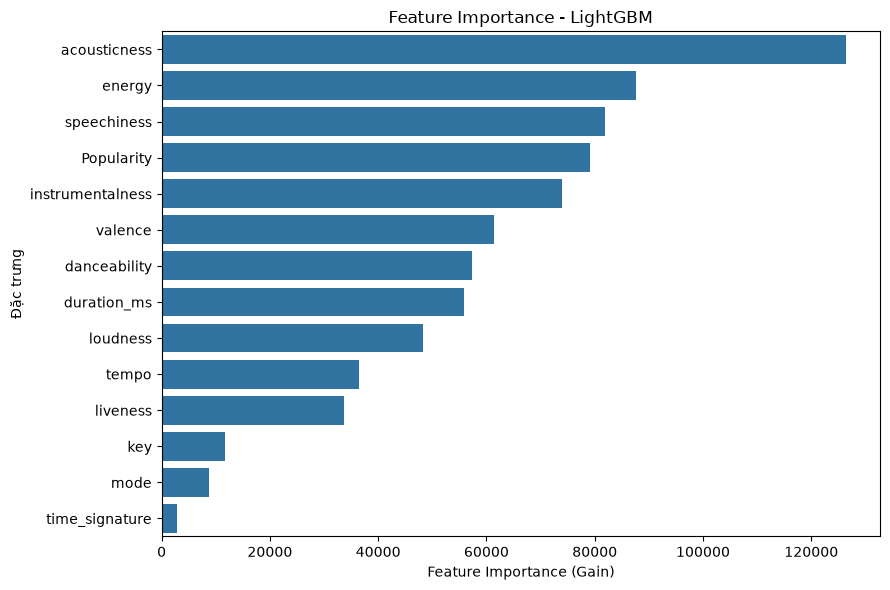

In [25]:
# Chọn mô hình có Macro F1 tốt hơn
if result_lgbm_balanced["F1 Macro"] >= result_lgbm_base["F1 Macro"]:
    best_lgbm_model = lgbm_model_balanced
    best_lgbm_name = "LightGBM Class Weight"
else:
    best_lgbm_model = lgbm_model_base
    best_lgbm_name = "LightGBM Baseline"

print("Mô hình LightGBM được chọn:", best_lgbm_name)

# Thống kê mức độ quan trọng của các đặc trưng
feature_importance = pd.Series(
    best_lgbm_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=feature_importance.values,
    y=feature_importance.index,
    color="tab:blue"
)

plt.xlabel("Feature Importance (Gain)")
plt.ylabel("Đặc trưng")
plt.title("Feature Importance - LightGBM")
plt.tight_layout()
plt.show()


#### 5.2 Mô hình XGBoost

In [2]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Tính trọng số để xử lý mất cân bằng dữ liệu
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Khởi tạo mô hình
xgb_model = XGBClassifier(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="multi:softprob",
    num_class=11,
    eval_metric="mlogloss",
    random_state=SEED,
    n_jobs=-1,
    tree_method="hist"
)

# Huấn luyện mô hình trên tập train
xgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

# Dự đoán trên tập validation
y_val_pred_xgb = xgb_model.predict(X_val)

# Đánh giá mô hình
xgb_accuracy = accuracy_score(y_val, y_val_pred_xgb)
xgb_f1_macro = f1_score(y_val, y_val_pred_xgb, average="macro")
xgb_f1_weighted = f1_score(y_val, y_val_pred_xgb, average="weighted")

print("KẾT QUẢ XGBOOST")
print(f"Accuracy:    {xgb_accuracy:.4f}")
print(f"F1 Macro:    {xgb_f1_macro:.4f}")
print(f"F1 Weighted: {xgb_f1_weighted:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_xgb,
    zero_division=0
))

# Ma trận nhầm lẫn
cm_xgb = confusion_matrix(
    y_val,
    y_val_pred_xgb,
    labels=np.arange(11)
)

plt.figure(figsize=(10, 8))

disp_xgb = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=np.arange(11)
)

disp_xgb.plot(cmap="Blues", xticks_rotation=45)

plt.title("Confusion Matrix - XGBoost")
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'matplotlib.backends.registry'

#### 5.3 Mô hình Random Forest

KẾT QUẢ RANDOM FOREST
Accuracy:    0.4337
F1 Macro:    0.4448
F1 Weighted: 0.4194

Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.40      0.31       100
           1       0.04      0.02      0.03       220
           2       0.33      0.50      0.40       204
           3       0.51      0.55      0.53        64
           4       0.37      0.48      0.42        62
           5       0.68      0.76      0.72       231
           6       0.28      0.22      0.25       414
           7       0.67      0.92      0.78        92
           8       0.51      0.68      0.58       297
           9       0.47      0.52      0.49       404
          10       0.48      0.35      0.40       792

    accuracy                           0.43      2880
   macro avg       0.42      0.49      0.44      2880
weighted avg       0.42      0.43      0.42      2880



<Figure size 1000x800 with 0 Axes>

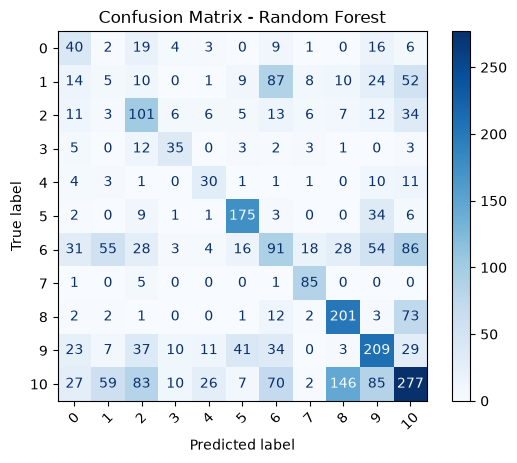

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Khởi tạo mô hình
rf_model = RandomForestClassifier(
    n_estimators=400,
    max_features="sqrt",
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

# Huấn luyện mô hình trên tập train
rf_model.fit(X_train, y_train)

# Dự đoán trên tập validation
y_val_pred_rf = rf_model.predict(X_val)

# Đánh giá mô hình
rf_accuracy = accuracy_score(y_val, y_val_pred_rf)
rf_f1_macro = f1_score(y_val, y_val_pred_rf, average="macro")
rf_f1_weighted = f1_score(y_val, y_val_pred_rf, average="weighted")

print("KẾT QUẢ RANDOM FOREST")
print(f"Accuracy:    {rf_accuracy:.4f}")
print(f"F1 Macro:    {rf_f1_macro:.4f}")
print(f"F1 Weighted: {rf_f1_weighted:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf))

# Ma trận nhầm lẫn
cm_rf = confusion_matrix(y_val, y_val_pred_rf)

plt.figure(figsize=(10, 8))
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf)
disp_rf.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix - Random Forest")
plt.show()

### 6. Tinh chỉnh siêu tham số

### 7. Đánh giá mô hình